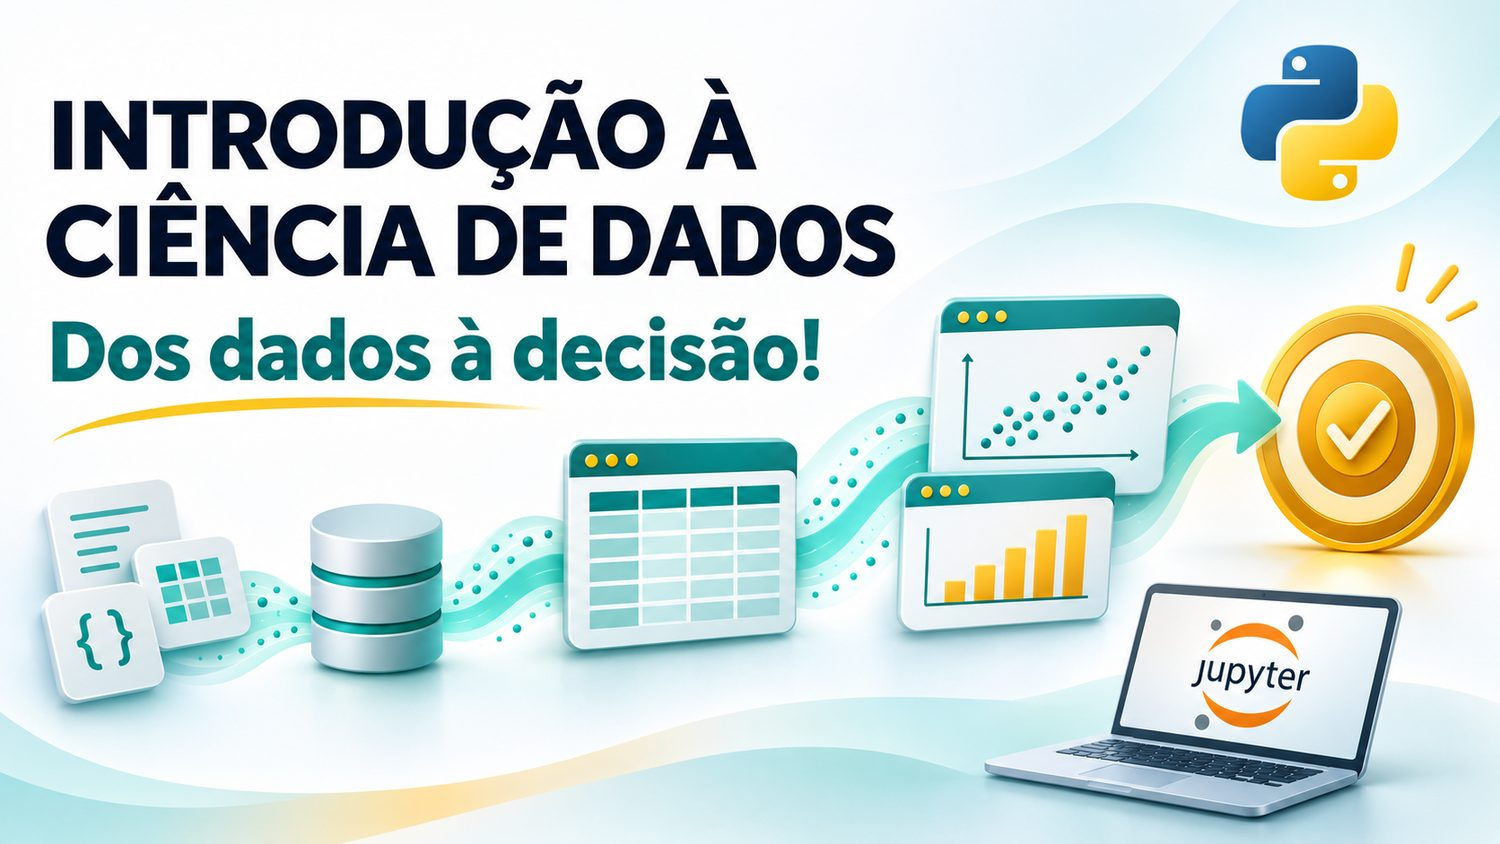

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/05_Equidade.ipynb)

# Capítulo 5 – Equidade: para quem é que o modelo funciona?

Um modelo pode ter boas métricas globais e tratar grupos de pessoas de maneiras muito diferentes. A ficha do capítulo anterior mostrou-o: a lista de risco apanha 72% das desistências na zona rural e 29% na urbana. Isto é injusto? A resposta honesta é «depende», e este capítulo é sobre de que é que depende. Não há uma métrica que resolva a questão; há perguntas que têm de ser feitas, e escolhas que têm de ser assumidas.

> **Objetivos:** avaliar um modelo por grupo; perceber que a mesma diferença pode prejudicar grupos diferentes conforme o uso; saber porque retirar um atributo sensível não chega; conhecer três definições de equidade e porque não se podem cumprir todas ao mesmo tempo; reconhecer as origens do enviesamento, dos dados ao uso; distinguir o que se resolve no modelo do que se resolve fora dele.

**Pré-requisitos:** capítulos 1 a 4, e o capítulo 1 do módulo 6 (matriz de confusão e limiar).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_formandos(n=6000, semente=97, com_transporte=False):
    """Gera formandos de um centro de formação profissional fictício (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    zona = rng.choice(["urbana", "rural"], n, p=[0.78, 0.22])
    rural = zona == "rural"
    idade = rng.normal(34, 10, n).clip(18, 62).round()
    escolaridade = rng.choice(["básico", "secundário", "superior"], n, p=[0.3, 0.5, 0.2])
    empregado = rng.random(n) < 0.45
    distancia = np.where(rural, rng.gamma(4.0, 6.0, n), rng.gamma(2.0, 2.5, n)).clip(0.5, 70).round(1)
    computador = rng.random(n) < np.where(rural, 0.62, 0.84)
    nota_inicial = (rng.normal(58, 15, n) + 6 * (escolaridade == "superior") - 5 * (escolaridade == "básico")).clip(5, 100).round()
    transporte_irregular = rural & (rng.random(n) < 0.30)                     # não fica registado em lado nenhum
    faltas = rng.poisson(np.clip(1.0 + 0.9 * empregado + 0.035 * distancia - 0.012 * (nota_inicial - 58) + 0.6 * ~computador, 0.15, None))
    z = (-2.95 + 0.42 * faltas + 0.55 * empregado - 0.022 * (nota_inicial - 58) + 0.55 * ~computador + 0.012 * distancia + 1.7 * transporte_irregular)
    desistiu = rng.random(n) < 1 / (1 + np.exp(-z))
    tabela = pd.DataFrame({"idade": idade, "zona": zona, "escolaridade": escolaridade, "empregado": empregado, "distancia_km": distancia,
                           "tem_computador": computador, "nota_inicial": nota_inicial, "faltas_primeiro_mes": faltas, "desistiu": desistiu})
    if com_transporte:                               # só para o capítulo 5: num caso real esta coluna não existe
        tabela["transporte_irregular"] = transporte_irregular
    return tabela


formandos = gerar_formandos()
formandos.head()

,idade,zona,escolaridade,empregado,distancia_km,tem_computador,nota_inicial,faltas_primeiro_mes,desistiu
0,44.0,urbana,secundário,True,3.3,True,58.0,3,False
1,44.0,urbana,secundário,True,4.5,False,56.0,3,False
2,40.0,urbana,secundário,True,1.8,True,79.0,0,False
3,54.0,rural,básico,True,33.4,False,65.0,6,True
4,47.0,urbana,secundário,True,3.8,True,40.0,0,False


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ["idade", "distancia_km", "nota_inicial", "faltas_primeiro_mes", "empregado", "tem_computador"]
desenvolvimento, teste = train_test_split(formandos, test_size=0.3, random_state=0, stratify=formandos["desistiu"])
real = teste["desistiu"].to_numpy()
rural = (teste["zona"] == "rural").to_numpy()


def treinar(colunas_numericas, colunas_nominais, alvo="desistiu"):
    passos = [("num", StandardScaler(), colunas_numericas)] + ([("cat", OneHotEncoder(), colunas_nominais)] if colunas_nominais else [])
    modelo = make_pipeline(ColumnTransformer(passos), LogisticRegression(max_iter=2000))
    return modelo.fit(desenvolvimento[colunas_numericas + colunas_nominais], desenvolvimento[alvo] if isinstance(alvo, str) else alvo)


modelo = treinar(numericas, ["zona", "escolaridade"])
risco = modelo.predict_proba(teste[numericas + ["zona", "escolaridade"]])[:, 1]
limiar = float(np.quantile(risco, 0.80))                          # a equipa acompanha o quinto de maior risco

## O mesmo limiar, dois grupos

Para cada grupo, as quatro contagens da matriz de confusão e as taxas que delas saem.

In [4]:
def por_grupo(assinalado, real, grupo, nomes=("zona urbana", "zona rural")):
    """Resumo por grupo de uma política de acompanhamento."""
    linhas = {}
    for nome, filtro in zip(nomes, [~grupo, grupo]):
        a, y = assinalado[filtro], real[filtro]
        linhas[nome] = {"formandos": int(filtro.sum()), "desistem (%)": y.mean() * 100, "assinalados (%)": a.mean() * 100,
                        "desistências apanhadas (%)": (a & y).sum() / y.sum() * 100,
                        "falsos alarmes (%)": (a & ~y).sum() / (~y).sum() * 100,
                        "assinalados que desistem (%)": (a & y).sum() / max(a.sum(), 1) * 100}
    return pd.DataFrame(linhas).round(0)


unico = risco >= limiar
resumo = por_grupo(unico, real, rural)
resumo

,zona urbana,zona rural
formandos,1390.0,410.0
desistem (%),17.0,40.0
assinalados (%),12.0,48.0
desistências apanhadas (%),29.0,72.0
falsos alarmes (%),8.0,32.0
assinalados que desistem (%),42.0,60.0


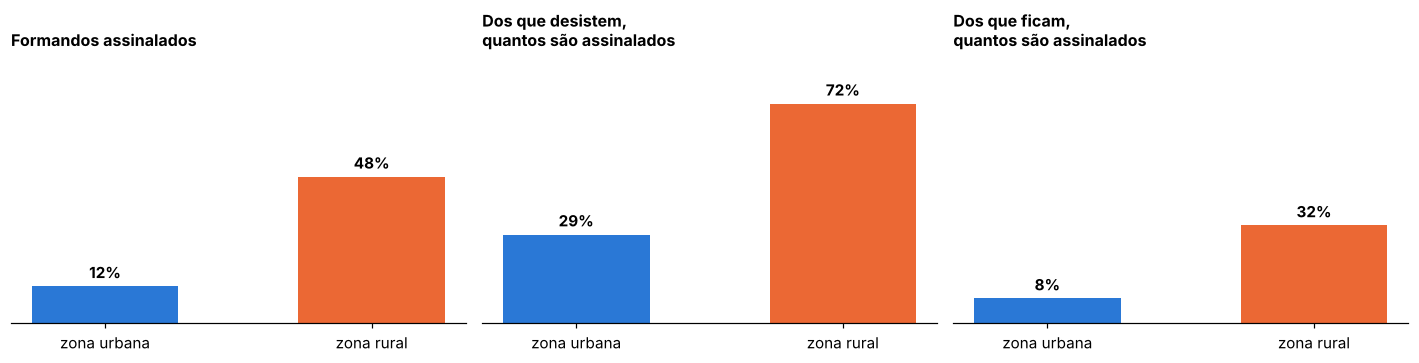

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, linha, titulo in zip(eixos, ["assinalados (%)", "desistências apanhadas (%)", "falsos alarmes (%)"],
                             ["Formandos assinalados", "Dos que desistem,\nquantos são assinalados", "Dos que ficam,\nquantos são assinalados"]):
    barras = ax.bar(["zona urbana", "zona rural"], resumo.loc[linha], color=[AZUL, LARANJA], width=0.55)
    ax.bar_label(barras, fmt="%.0f%%", padding=3, fontweight="bold")
    ax.set_ylim(0, 88)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.set_title(titulo, fontsize=10.5)
plt.tight_layout()
plt.show()

Com um só limiar para todos:

- quase **metade** dos formandos rurais é assinalada, contra um em cada oito urbanos;
- entre os que acabam por desistir, a lista apanha **sete em cada dez** rurais e **três em cada dez** urbanos;
- entre os que ficam até ao fim, um terço dos rurais é assinalado sem razão, contra menos de um décimo dos urbanos.

O modelo trata os dois grupos de forma muito diferente. Falta saber se isso é um problema, e para quem.

## Quem é prejudicado depende do que se faz com a lista

A mesma tabela lê-se de duas maneiras opostas, conforme a ação que se segue.

| | Se ser assinalado traz uma **ajuda** | Se ser assinalado traz uma **penalização** |
| --- | --- | --- |
| Exemplo | Tutoria, apoio ao transporte | Recusar a inscrição, exigir uma caução |
| O erro que prejudica a pessoa | Não ser assinalado e precisar (falso negativo) | Ser assinalado sem razão (falso alarme) |
| Métrica a comparar entre grupos | Desistências apanhadas | Falsos alarmes |
| Grupo prejudicado, neste modelo | **Urbanos**: 7 em cada 10 dos que desistem não recebem ajuda | **Rurais**: um terço dos que iam ficar é penalizado |

No centro de formação, a lista serve para dar apoio. Os prejudicados são os formandos **urbanos** em risco, que o modelo vê pior. Se o mesmo modelo fosse usado para selecionar candidatos, os prejudicados seriam os **rurais**.

> **Não se pode avaliar a equidade de um modelo sem saber para que é usado.** É mais uma razão para a ficha do modelo dizer o uso previsto e os usos excluídos.

## O modelo está «errado»?

A primeira suspeita é que o modelo esteja enviesado contra um dos grupos. Verificamos se o risco previsto corresponde ao que acontece **em cada grupo**.

In [6]:
linhas = {}
for nome, filtro in [("zona urbana", ~rural), ("zona rural", rural)]:
    linhas[nome] = {"risco médio previsto (%)": risco[filtro].mean() * 100, "desistências observadas (%)": real[filtro].mean() * 100, "AUC": roc_auc_score(real[filtro], risco[filtro])}
pd.DataFrame(linhas).round(2)

,zona urbana,zona rural
risco médio previsto (%),18.99,38.46
desistências observadas (%),17.27,40.24
AUC,0.71,0.76


O modelo está razoavelmente **calibrado** nos dois grupos: prevê cerca de 19% de desistências na zona urbana, onde há 17%, e cerca de 38% na rural, onde há 40%. E ordena os formandos rurais tão bem ou melhor do que os urbanos.

Não é um modelo que «não gosta» de um grupo. Os formandos rurais desistem **de facto** mais do dobro, e o modelo aprendeu isso. Com um limiar único, um grupo com mais risco fica com mais gente acima da linha. A desigualdade nas tabelas vem de uma diferença **real** nos dados.

Isto muda a pergunta. Já não é «como corrijo o modelo?», mas «o que quero que a lista faça perante uma diferença que existe?».

## Retirar o atributo não resolve

A solução que ocorre a toda a gente: o modelo não devia usar a zona. Retira-se a coluna.

In [7]:
sem_zona = treinar(numericas, ["escolaridade"])
risco_sem_zona = sem_zona.predict_proba(teste[numericas + ["escolaridade"]])[:, 1]
adivinhar = treinar(numericas, ["escolaridade"], alvo=desenvolvimento["zona"] == "rural")
print(f"Um modelo que tenta adivinhar a zona a partir das outras colunas tem uma AUC de {roc_auc_score(rural, adivinhar.predict_proba(teste[numericas + ['escolaridade']])[:, 1]):.2f}\n")

comparacao = pd.concat({"com a zona": por_grupo(unico, real, rural).loc[["assinalados (%)", "desistências apanhadas (%)"]],
                        "sem a zona": por_grupo(risco_sem_zona >= np.quantile(risco_sem_zona, 0.8), real, rural).loc[["assinalados (%)", "desistências apanhadas (%)"]]})
comparacao

Um modelo que tenta adivinhar a zona a partir das outras colunas tem uma AUC de 0.97



zona urbana  zona rural
com a zona assinalados (%)                    12.0        48.0
           desistências apanhadas (%)         29.0        72.0
sem a zona assinalados (%)                    13.0        45.0
           desistências apanhadas (%)         30.0        68.0

Quase nada muda. As outras colunas, sobretudo a distância, permitem reconstituir a zona quase na perfeição. Chama-se a estas colunas ***proxies***: substitutos que transportam a mesma informação.

A ideia de que um modelo é justo se não «vir» o atributo sensível (equidade por desconhecimento) falha quase sempre, por duas razões:

- os atributos sensíveis deixam marcas em muitos outros (a morada, o nome, os horários, as compras);
- sem a coluna, **deixa de se poder medir** o que o modelo faz a cada grupo. Retirá-la dos dados de avaliação é tapar os olhos.

A prática recomendada é a oposta: o atributo sensível pode não entrar no modelo, e **tem de estar disponível para a avaliação**.

## Três ideias de «justo»

Há várias maneiras de definir tratamento igual. As três mais usadas:

| Critério | Em palavras | Compara entre grupos | Faz sentido quando |
| --- | --- | --- | --- |
| **Paridade** | A mesma fração de cada grupo é assinalada | Assinalados (%) | Os recursos devem ser repartidos em proporção ao tamanho dos grupos |
| **Igualdade de oportunidades** | Quem precisa tem a mesma probabilidade de ser assinalado, em qualquer grupo | Desistências apanhadas (%) | O erro grave é não ajudar quem precisa |
| **Igual significado da pontuação** | Um risco de 30% quer dizer o mesmo em qualquer grupo | Calibração por grupo | A pontuação é lida por pessoas, que decidem caso a caso |

O nosso modelo cumpre razoavelmente a terceira e falha por muito as duas primeiras. Podemos forçar qualquer uma das outras usando **um limiar por grupo**, mantendo a capacidade total de 20%.

In [8]:
def politica(limiar_urbano, limiar_rural):
    return np.where(rural, risco >= limiar_rural, risco >= limiar_urbano)


def procurar(criterio):
    """Procura o par de limiares que acompanha 20% dos formandos e minimiza o critério."""
    melhor = None
    for lu in np.linspace(0.10, 0.60, 101):
        for lr in np.linspace(0.10, 0.85, 151):
            a = politica(lu, lr)
            if abs(a.mean() - 0.20) < 0.004:
                valor = criterio(a)
                if melhor is None or valor < melhor[0]:
                    melhor = (valor, lu, lr)
    return melhor[1], melhor[2]


apanhadas = lambda a, filtro: (a & real & filtro).sum() / (real & filtro).sum()
politicas = {"Um limiar para todos": (limiar, limiar),
             "Paridade": procurar(lambda a: abs(a[rural].mean() - a[~rural].mean())),
             "Igualdade de oportunidades": procurar(lambda a: abs(apanhadas(a, rural) - apanhadas(a, ~rural)))}
linhas = {}
for nome, (lu, lr) in politicas.items():
    a = politica(lu, lr)
    r = por_grupo(a, real, rural)
    linhas[nome] = {"limiar urbano": lu, "limiar rural": lr, "assinalados: urbana | rural": f"{r.loc['assinalados (%)', 'zona urbana']:.0f}% | {r.loc['assinalados (%)', 'zona rural']:.0f}%",
                    "apanhadas: urbana | rural": f"{r.loc['desistências apanhadas (%)', 'zona urbana']:.0f}% | {r.loc['desistências apanhadas (%)', 'zona rural']:.0f}%",
                    "desistências apanhadas, no total": f"{(a & real).sum() / real.sum():.0%}", "em cada 100 formandos": round((a & real).sum() / len(real) * 100, 1)}
tabela = pd.DataFrame(linhas).T
tabela.round(2)

,limiar urbano,limiar rural,assinalados: urbana | rural,apanhadas: urbana | rural,"desistências apanhadas, no total",em cada 100 formandos
Um limiar para todos,0.359554,0.359554,12% | 48%,29% | 72%,46%,10.4
Paridade,0.285,0.58,20% | 20%,42% | 36%,40%,8.9
Igualdade de oportunidades,0.29,0.535,19% | 24%,40% | 41%,40%,9.1


As três linhas são três políticas possíveis com a **mesma equipa** e o **mesmo modelo**.

- **Um limiar para todos** apanha o maior número de desistências. É a política mais eficiente, e concentra a ajuda na zona rural.
- **Igualdade de oportunidades** dá a um formando em risco a mesma probabilidade de ser acompanhado, more onde morar. Para isso, o limiar rural tem de ser quase o dobro do urbano: um formando rural precisa de um risco muito mais alto para entrar na lista. No total apanham-se menos desistências.
- **Paridade** assinala a mesma fração de cada grupo. Tem um custo parecido.

Repara no que **não** existe na tabela: uma linha que cumpra tudo. Não é falta de habilidade.

> Quando os grupos têm taxas diferentes do resultado, **nenhum modelo imperfeito consegue**, ao mesmo tempo, dar à pontuação o mesmo significado nos dois grupos e ter as mesmas taxas de erro em ambos. É um resultado matemático, e não uma limitação da técnica.

Escolher uma definição de equidade é abdicar das outras. A escolha é uma **decisão de valores**, que pertence a quem dirige o centro e a quem é afetado. O trabalho de quem analisa é pôr a tabela em cima da mesa, com os custos de cada linha, e não escolher sozinho, nem esconder que há uma escolha.

### O custo, em pessoas

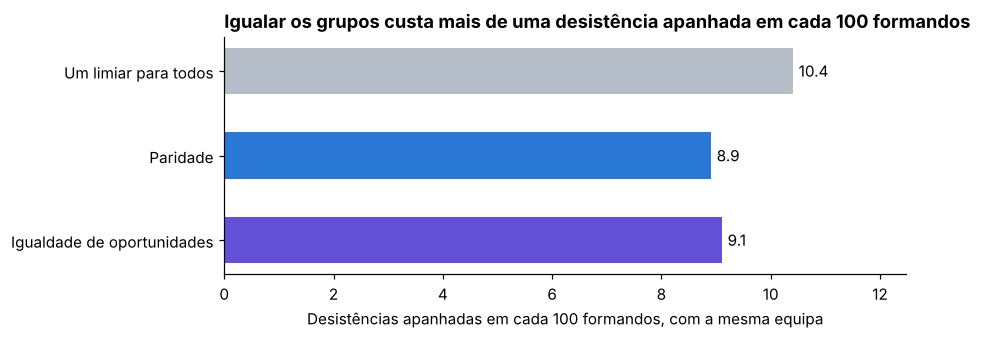

In [9]:
por_100 = tabela["em cada 100 formandos"].astype(float)
fig, ax = plt.subplots(figsize=(8, 2.8))
barras = ax.barh(por_100.index, por_100, color=[CINZA, AZUL, VIOLETA], height=0.55)
ax.bar_label(barras, fmt="%.1f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, por_100.max() * 1.2)
ax.set_xlabel("Desistências apanhadas em cada 100 formandos, com a mesma equipa")
ax.set_title("Igualar os grupos custa mais de uma desistência apanhada em cada 100 formandos")
plt.show()

Com a capacidade fixa, igualar os grupos custa entre uma e duas desistências apanhadas em cada 100 formandos: para um centro com 600 formandos por ano, oito ou nove pessoas. É o preço de não deixar para trás os formandos urbanos em risco. Pode ser um preço que o centro quer pagar; pode não ser. O que não pode é ser pago, ou recusado, sem ninguém saber.

Há uma terceira via, muitas vezes a melhor: **aumentar a capacidade** até o grupo pior servido chegar a um nível aceitável. A equidade discute-se quase sempre como um problema de repartição, e muitas vezes é um problema de recursos.

## De onde vem o enviesamento

Neste caso, o modelo reflete uma diferença real. Noutros, é o próprio processo que introduz distorções. Convém percorrer o caminho todo.

| Origem | O que acontece | Exemplo |
| --- | --- | --- |
| **Histórica** | Os dados registam um mundo desigual | Os formandos rurais desistem mais porque o transporte é pior |
| **Representação** | Um grupo tem poucos casos | Com 22% de rurais, o desempenho nesse grupo conhece-se com menos precisão (capítulo 3) |
| **Medição** | Um atributo ou o alvo é medido de forma diferente entre grupos | As faltas são registadas com mais rigor num dos polos |
| **Rótulo** | O alvo mede uma decisão passada, e não o facto | «Foi excluído por faltas» depende do formador, e não só do formando |
| **Agregação** | Uma só relação para grupos que funcionam de forma diferente | As faltas querem dizer coisas diferentes para quem trabalha e para quem não trabalha |
| **Utilização** | O modelo é usado fora do âmbito | Uma lista feita para apoiar passa a ser usada para selecionar |
| **Retroação** | As decisões do modelo alteram os dados futuros | Quem é acompanhado desiste menos; o modelo seguinte aprende que esse perfil «não é de risco» |

A última linha merece atenção: um modelo em uso muda o mundo que mede. Se o acompanhamento funcionar, os dados do ano seguinte dirão que os formandos assinalados afinal não desistiam, e um modelo treinado com eles deixará de os assinalar.

## O que o modelo não vê

Como os dados são sintéticos, podemos espreitar uma coluna que na realidade **ninguém regista**: se o formando depende de um transporte irregular.

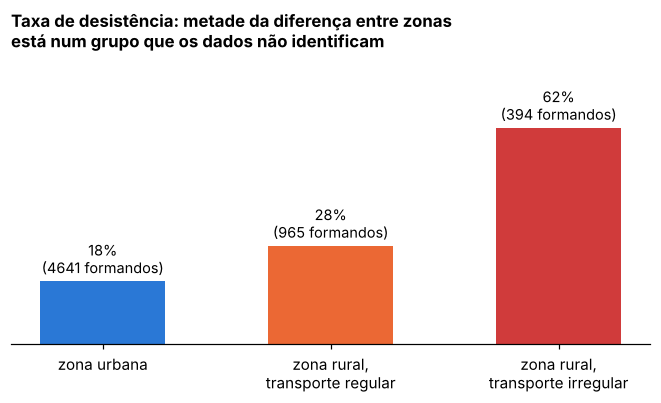

In [10]:
completo = gerar_formandos(com_transporte=True)
grupos = completo.assign(grupo=np.select([completo["zona"] == "urbana", completo["transporte_irregular"]], ["zona urbana", "zona rural,\ntransporte irregular"], "zona rural,\ntransporte regular"))
taxas = grupos.groupby("grupo")["desistiu"].agg(["mean", "size"]).loc[["zona urbana", "zona rural,\ntransporte regular", "zona rural,\ntransporte irregular"]]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
barras = ax.bar(taxas.index, taxas["mean"] * 100, color=[AZUL, LARANJA, MAU], width=0.55)
ax.bar_label(barras, labels=[f"{m:.0%}\n({n} formandos)" for m, n in zip(taxas["mean"], taxas["size"])], padding=3, fontsize=9.5)
ax.set_ylim(0, 82)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_title("Taxa de desistência: metade da diferença entre zonas\nestá num grupo que os dados não identificam", loc="left", fontsize=11)
plt.show()

Cerca de metade do excesso de desistências na zona rural vem de um grupo de formandos com transporte irregular, que desiste três vezes mais do que os urbanos. O modelo não sabe quem são; só sabe que são rurais, e sobe o risco a **todos** os rurais.

A consequência prática vai além do modelo:

- nenhuma escolha de limiar resolve isto. O que resolve é **recolher a informação** (perguntar pelo transporte na inscrição) ou, melhor, **agir sobre a causa** (um apoio ao transporte);
- a análise de equidade serviu para descobrir um problema do **centro**, e não do modelo.

É um padrão frequente. Uma diferença entre grupos num modelo é muitas vezes o sinal de uma diferença de condições que estava por ver, e a resposta mais útil está fora do modelo.

## O que fazer, na prática

| Momento | Pergunta | Ação |
| --- | --- | --- |
| **Antes de construir** | Quem é afetado? O que acontece a quem é assinalado, e a quem não é? | Escrever o uso previsto; ouvir quem é afetado |
| **Nos dados** | Que grupos importam? Há casos suficientes de cada um? O alvo é medido da mesma forma em todos? | Guardar os atributos sensíveis para avaliação; documentar na ficha dos dados |
| **Na avaliação** | O desempenho é parecido entre grupos? Com que margem? | Tabela por grupo, com intervalos |
| **Na decisão** | Que critério de equidade corresponde ao uso? Quanto custa? | Apresentar as políticas possíveis e os seus custos a quem decide |
| **Em uso** | Há alguém a rever os casos? As pessoas podem contestar? | Decisão final humana nos casos com consequências; um canal para reclamar |
| **Ao longo do tempo** | As diferenças entre grupos estão a mudar? | Incluir as métricas por grupo na vigilância (capítulo 4) |

Duas notas finais.

**Os grupos cruzam-se.** Avaliámos por zona. Um modelo pode funcionar bem para rurais e para mulheres, em média, e mal para mulheres rurais. Quanto mais se cruza, mais pequenos ficam os grupos e mais largas as margens: não há como testar tudo, e é preciso escolher os cruzamentos que importam com quem conhece o terreno.

**A lei também conta.** Em muitos contextos (emprego, crédito, seguros, acesso a serviços públicos) há regras sobre discriminação e sobre decisões automatizadas, e o Regulamento Europeu de Inteligência Artificial classifica como de risco elevado vários usos em educação e formação. Este capítulo não substitui aconselhamento jurídico: num projeto real, estas questões discutem-se com quem tem essa competência, desde o início.

## Exercícios

### `Exercício 1` – Quem é prejudicado?

Um modelo de triagem telefónica de um serviço de saúde decide quem é encaminhado para uma consulta no próprio dia. Tem uma sensibilidade de 90% para os utentes com menos de 65 anos e de 75% para os de 65 ou mais; a taxa de falsos alarmes é de 20% e 12%, respetivamente. Que grupo é prejudicado? Que critério de equidade faz mais sentido aqui?

<details>
<summary><b>Ver uma solução possível</b></summary>

Ser assinalado traz um benefício (a consulta). O erro que prejudica a pessoa é o falso negativo: precisar e não ser encaminhado. Os utentes mais velhos têm uma sensibilidade mais baixa: um em cada quatro dos que precisavam não é encaminhado, contra um em cada dez dos mais novos. São os **mais velhos** os prejudicados, e de forma grave, porque são também os de maior risco clínico.

O critério adequado é a **igualdade de oportunidades**: quem precisa deve ter a mesma probabilidade de ser encaminhado, em qualquer grupo. Baixar o limiar para os mais velhos aumentaria os seus falsos alarmes, que aqui custam uma consulta desnecessária: um preço aceitável perante o erro oposto.

</details>

### `Exercício 2` – Avaliar por outro grupo

Repete a tabela `por_grupo` para os formandos que trabalham e os que não trabalham (coluna `empregado`), com o limiar único. As diferenças são tão grandes como entre zonas? O modelo está calibrado nos dois grupos?

In [11]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
empregado = teste["empregado"].to_numpy()
print(por_grupo(unico, real, empregado, nomes=("não trabalha", "trabalha")))
for nome, filtro in [("não trabalha", ~empregado), ("trabalha", empregado)]:
    print(f"{nome}: risco médio previsto {risco[filtro].mean():.0%} | desistências observadas {real[filtro].mean():.0%}")
```

Há uma diferença no mesmo sentido: quem trabalha desiste mais, é mais assinalado e tem uma maior parte das suas desistências apanhada. O modelo está calibrado nos dois grupos. O mecanismo é o mesmo da zona: taxas diferentes, um limiar único. O que muda é o juízo: «trabalhar» é uma circunstância que o centro pode querer ter em conta de propósito (horários pós-laborais), e talvez ninguém considere injusto dar mais atenção a esse grupo. A mesma estatística pode levantar um problema num atributo e não levantar noutro: depende do que o atributo representa.

</details>

### `Exercício 3` – Mais capacidade em vez de repartição

Mantendo o limiar único, que capacidade (percentagem de formandos acompanhados) seria precisa para a lista apanhar pelo menos 40% das desistências na zona **urbana**? Quantas desistências se apanhariam no total, em cada 100 formandos?

In [12]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for capacidade in np.arange(0.20, 0.41, 0.02):
    a = risco >= np.quantile(risco, 1 - capacidade)
    urbana = apanhadas(a, ~rural)
    print(f"capacidade {capacidade:.0%}: urbana {urbana:.0%} | rural {apanhadas(a, rural):.0%} | total em cada 100: {(a & real).sum() / len(real) * 100:.1f}")
    if urbana >= 0.40:
        break
```

É preciso acompanhar 28% dos formandos, em vez de 20%. Com essa capacidade, a zona urbana chega ao nível que a política de igualdade de oportunidades lhe dava, a zona rural não perde nada e o total de desistências apanhadas **sobe** em vez de descer. Custa mais tutoras. É a comparação que a direção precisa de ver: repartir de outra forma o que há, ou reforçar a equipa.

</details>

### `Exercício 4` – Um atributo que substitui outro

Treina um modelo sem a zona **e sem a distância**. O que acontece às percentagens de formandos assinalados em cada zona, e ao total de desistências apanhadas? Vale a pena?

In [13]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
sem_distancia = [c for c in numericas if c != "distancia_km"]
m = treinar(sem_distancia, ["escolaridade"])
r = m.predict_proba(teste[sem_distancia + ["escolaridade"]])[:, 1]
a = r >= np.quantile(r, 0.8)
print(por_grupo(a, real, rural).loc[["assinalados (%)", "desistências apanhadas (%)"]])
print(f"Total de desistências apanhadas: {(a & real).sum() / real.sum():.0%} (com todas as colunas: {(unico & real).sum() / real.sum():.0%})")
```

A diferença entre zonas diminui e não desaparece: outras colunas (ter computador, as próprias faltas) também diferem entre zonas. O total de desistências apanhadas baixa. Fica-se com um modelo pior, que continua a tratar os grupos de forma diferente, e com menos controlo sobre **quanto**. Retirar atributos às cegas é a forma menos eficaz de procurar equidade; escolher um critério e ajustar a política, como fizemos com os limiares, é mais transparente e dá melhor resultado.

</details>

## Verifica o que aprendeste

- [ ] Sei avaliar um modelo por grupo.
- [ ] Sei porque o grupo prejudicado depende do uso que se dá à previsão.
- [ ] Sei distinguir um modelo descalibrado de um modelo que reflete taxas diferentes.
- [ ] Sei porque retirar o atributo sensível não chega, e porque é preciso guardá-lo para avaliar.
- [ ] Sei explicar a paridade, a igualdade de oportunidades e o igual significado da pontuação.
- [ ] Sei que estes critérios não se cumprem todos ao mesmo tempo, e que a escolha é de valores.
- [ ] Sei enumerar as origens do enviesamento, dos dados à utilização.
- [ ] Sei que a resposta mais útil está muitas vezes fora do modelo.

## Leitura recomendada

- https://fairmlbook.org
- https://en.wikipedia.org/wiki/Fairness_(machine_learning)
- https://arxiv.org/abs/1609.05807
- https://artificialintelligenceact.eu